# Лабораторна робота 10. Завдання 3. Аугментація і тонке налаштування на обмеженому наборі коти-собаки: InceptionV3

## Завантаження набору даних з Google Диска

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
import glob, shutil

# шукаємо архів dogs-vs-cats.zip з Kaggle у будь-якій папці Google Диска
found = glob.glob('/content/drive/MyDrive/**/dogs-vs-cats*.zip', recursive=True)
print(found)
assert found, 'Архів dogs-vs-cats.zip не знайдено на Google Диску'
shutil.copy(found[0], '/content/dogs-vs-cats.zip')

['/content/drive/MyDrive/dogs-vs-cats.zip']


'/content/dogs-vs-cats.zip'

In [3]:
!unzip -q -o /content/dogs-vs-cats.zip -d /content/dogs-vs-cats
!unzip -q -o /content/dogs-vs-cats/train.zip -d /content/dogs-vs-cats
!ls /content/dogs-vs-cats/train | wc -l

25000


## Обмежений набір даних: 2000 / 500 / 500 зображень кожного класу

In [4]:
%%writefile prepare_small_dataset.py
"""Підготовка обмеженого набору даних Dogs vs. Cats для лабораторної роботи 10.

З 25 000 зображень train.zip з Kaggle формується невеликий набір: по 2000 зображень кожного класу
для навчання, по 500 для перевірки і по 500 для тестування. Усі зображення в наборах різні.
"""
import os
import shutil

# Каталог з набором даних (розпакований train.zip з Kaggle)
data_dir = '/content/dogs-vs-cats/train'
# Каталог з даними для навчання
train_dir = 'train'
# Каталог з даними для перевірки
val_dir = 'val'
# Каталог з даними для тестування
test_dir = 'test'
# Кількість зображень одного класу в кожному наборі
nb_train, nb_val, nb_test = 2000, 500, 500


def create_directory(dir_name):
    """Створює каталог dir_name з підкаталогами cats і dogs (старий каталог видаляється)."""
    if os.path.exists(dir_name):
        shutil.rmtree(dir_name)
    os.makedirs(os.path.join(dir_name, "cats"))
    os.makedirs(os.path.join(dir_name, "dogs"))


def copy_images(start_index, end_index, source_dir, dest_dir):
    """Копіює зображення котів і собак з номерами від start_index до end_index у підкаталоги cats і dogs."""
    for i in range(start_index, end_index):
        shutil.copy2(os.path.join(source_dir, "cat." + str(i) + ".jpg"), os.path.join(dest_dir, "cats"))
        shutil.copy2(os.path.join(source_dir, "dog." + str(i) + ".jpg"), os.path.join(dest_dir, "dogs"))


for d in (train_dir, val_dir, test_dir):
    create_directory(d)

# 0-1999 - навчання, 2000-2499 - перевірка, 2500-2999 - тестування
copy_images(0, nb_train, data_dir, train_dir)
copy_images(nb_train, nb_train + nb_val, data_dir, val_dir)
copy_images(nb_train + nb_val, nb_train + nb_val + nb_test, data_dir, test_dir)

for d in (train_dir, val_dir, test_dir):
    print(d, ': cats -', len(os.listdir(os.path.join(d, "cats"))), ', dogs -', len(os.listdir(os.path.join(d, "dogs"))))


Writing prepare_small_dataset.py


In [6]:
!python prepare_small_dataset.py

train : cats - 2000 , dogs - 2000
val : cats - 500 , dogs - 500
test : cats - 500 , dogs - 500


## Структура каталогів

In [7]:
!find train val test -maxdepth 1 -type d | sort
!ls train/cats | head -3
!ls val/cats | head -3
!ls test/dogs | head -3

test
test/cats
test/dogs
train
train/cats
train/dogs
val
val/cats
val/dogs
cat.0.jpg
cat.1000.jpg
cat.1001.jpg
cat.2000.jpg
cat.2001.jpg
cat.2002.jpg
dog.2500.jpg
dog.2501.jpg
dog.2502.jpg


## Підключаємо бібліотеки

In [8]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Flatten, BatchNormalization
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.utils import load_img, img_to_array

## Генератори з аугментацією і без неї

In [9]:
# найкращі параметри класифікатора InceptionV3 з лабораторної роботи 9
CFG = {'dense': 256, 'dropout': 0.8, 'extra_dense': 0, 'optimizer': 'sgd', 'lr': 1e-3, 'batch': 50}
BATCH = CFG['batch']
EPOCHS = 15

In [10]:
img_width, img_height = 150, 150
input_shape = (img_width, img_height, 3)

# генератор з аугментацією для навчання (параметри з методички)
train_datagen = ImageDataGenerator(preprocessing_function=preprocess_input,
                                   rotation_range=40,
                                   width_shift_range=0.2,
                                   height_shift_range=0.2,
                                   zoom_range=0.2,
                                   horizontal_flip=True,
                                   fill_mode='nearest')
# генератор без аугментації: для перевірки, тестування і для навчання без аугментації
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)


def flow(datagen, directory, batch_size, shuffle):
    return datagen.flow_from_directory(directory, target_size=(img_width, img_height),
                                       batch_size=batch_size, class_mode='binary', shuffle=shuffle)


train_generator = flow(train_datagen, 'train', BATCH, True)
train_noaug_generator = flow(test_datagen, 'train', BATCH, True)
val_generator = flow(test_datagen, 'val', 50, False)
test_generator = flow(test_datagen, 'test', 50, False)
print(train_generator.class_indices)

Found 4000 images belonging to 2 classes.
Found 4000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
{'cats': 0, 'dogs': 1}


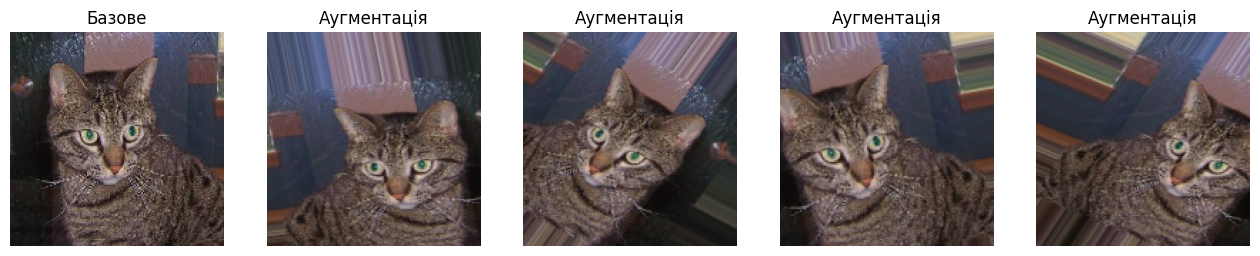

In [11]:
# як аугментація змінює одне зображення
img = load_img('train/cats/cat.1.jpg', target_size=(img_width, img_height))
x = np.expand_dims(img_to_array(img), axis=0)
plt.figure(figsize=(16, 4))
plt.subplot(1, 5, 1); plt.imshow(img); plt.title('Базове'); plt.axis('off')
aug_view = ImageDataGenerator(rotation_range=40, width_shift_range=0.2, height_shift_range=0.2,
                              zoom_range=0.2, horizontal_flip=True, fill_mode='nearest')
for i, batch in enumerate(aug_view.flow(x, batch_size=1)):
    plt.subplot(1, 5, i + 2); plt.imshow(batch[0].astype('uint8')); plt.title('Аугментація'); plt.axis('off')
    if i == 3:
        break
plt.show()

## Модель на основі InceptionV3

In [12]:
def plot_history(history, title):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(acc) + 1)
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='навчальна')
    plt.plot(epochs_range, val_acc, label='перевірочна')
    plt.title(title + ': точність'); plt.xlabel('Епоха'); plt.legend(); plt.grid()
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='навчальна')
    plt.plot(epochs_range, val_loss, label='перевірочна')
    plt.title(title + ': помилка (loss)'); plt.xlabel('Епоха'); plt.legend(); plt.grid()
    plt.show()

In [13]:



def load_base():
    net = InceptionV3(weights='imagenet', include_top=False, input_shape=input_shape)
    net.trainable = False
    return net


def make_optimizer(name, lr):
    return Adam(learning_rate=lr) if name == 'adam' else SGD(learning_rate=lr)


def create_model(net):
    """Складена мережа: заморожена згорткова частина + класифікатор з найкращими параметрами лабораторної 9."""
    model = Sequential()
    model.add(Input(shape=input_shape))
    model.add(net)
    model.add(Flatten())
    model.add(Dense(CFG['dense'], activation='relu'))
    model.add(Dropout(CFG['dropout']))
    if CFG['extra_dense']:
        model.add(Dense(CFG['extra_dense'], activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(loss='binary_crossentropy', optimizer=make_optimizer(CFG['optimizer'], CFG['lr']), metrics=['accuracy'])
    return model


def train(generator, title):
    net = load_base()
    model = create_model(net)
    history = model.fit(generator, steps_per_epoch=len(generator), epochs=EPOCHS,
                        validation_data=val_generator, validation_steps=len(val_generator), verbose=2)
    plot_history(history, title)
    scores = model.evaluate(test_generator, steps=len(test_generator), verbose=0)
    print(f"{title}: точність на тестових даних {scores[1]*100:.2f}%")
    results.append({'модель': title, 'навчальна, %': history.history['accuracy'][-1] * 100,
                    'перевірочна, %': history.history['val_accuracy'][-1] * 100, 'тестова, %': scores[1] * 100})
    return model, net


def unfreeze(net, n_blocks):
    """Розморожуємо останні модулі Inception (як у лабораторній 9), BatchNormalization залишаються замороженими."""
    after = {1: 'mixed9', 2: 'mixed8'}[n_blocks]
    net.trainable = True
    trainable = False
    for layer in net.layers:
        layer.trainable = trainable and not isinstance(layer, BatchNormalization)
        if layer.name == after:
            trainable = True


def fine_tune(model, net, n_blocks, title, epochs=5):
    """Тонке налаштування: розморожуємо n_blocks останніх блоків, мала швидкість навчання, як у лекції."""
    ft = create_model(load_base())
    ft.set_weights(model.get_weights())
    unfreeze(ft.layers[0], n_blocks)
    ft.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=1e-5), metrics=['accuracy'])
    trainable = sum(int(np.prod(w.shape)) for w in ft.trainable_weights)
    print(f"Розморожено блоків: {n_blocks}, параметрів навчається: {trainable:,}")
    history = ft.fit(train_generator, steps_per_epoch=len(train_generator), epochs=epochs,
                     validation_data=val_generator, validation_steps=len(val_generator), verbose=2)
    plot_history(history, title)
    scores = ft.evaluate(test_generator, steps=len(test_generator), verbose=0)
    print(f"{title}: точність на тестових даних {scores[1]*100:.2f}%")
    results.append({'модель': title, 'навчальна, %': history.history['accuracy'][-1] * 100,
                    'перевірочна, %': history.history['val_accuracy'][-1] * 100, 'тестова, %': scores[1] * 100})
    return ft


results = []

## Перенесення навчання без аугментації

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
80/80 - 35s - 441ms/step - accuracy: 0.8470 - loss: 0.5600 - val_accuracy: 0.9590 - val_loss: 0.1175
Epoch 2/15
80/80 - 10s - 129ms/step - accuracy: 0.9168 - loss: 0.2306 - val_accuracy: 0.9620 - val_loss: 0.1112
Epoch 3/15
80/80 - 10s - 127ms/step - accuracy: 0.9362 - loss: 0.1619 - val_accuracy: 0.9610 - val_loss: 0.1134
Epoch 4/15
80/80 - 10s - 123ms/step - accuracy: 0.9438 - loss: 0.1525 - val_accuracy: 0.9620 - val_loss: 0.1047
Epoch 5/15
80/80 - 11s - 137ms/step - accuracy: 0.9485 - loss: 0.1322 - val_accuracy: 0.9630 - val_loss: 0.0984
Epoch 6/15
80/80 - 9s - 117ms/step - accuracy: 0.9525 - loss: 0.1258 - val_accuracy: 0.9630 - val_loss: 0.1055
Epoch 7/15
80/80 - 11s - 132ms/step - accuracy: 0.9610 - loss: 0.1084 - val_accuracy: 0.9630 - val_loss: 0.1105
Epoch 8/15
80/80 - 11s - 135ms/step - accuracy: 0.9610 - loss: 0.1024 - val_accuracy: 0.9650 - val_loss: 0.1014
Epoch 9/15
80/80 - 10s - 128ms/step - accuracy: 0.9592

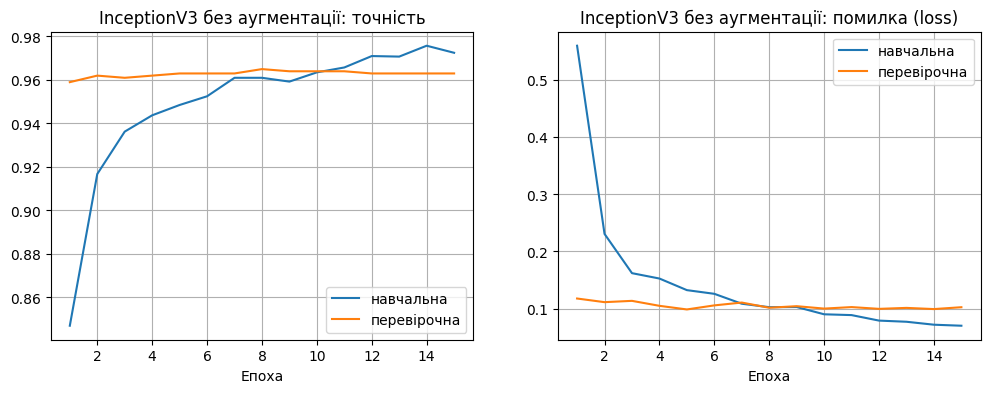

InceptionV3 без аугментації: точність на тестових даних 95.30%


In [14]:
model_noaug, _ = train(train_noaug_generator, 'InceptionV3 без аугментації')

## Перенесення навчання з аугментацією

Epoch 1/15
80/80 - 48s - 602ms/step - accuracy: 0.7812 - loss: 0.7154 - val_accuracy: 0.9450 - val_loss: 0.1256
Epoch 2/15
80/80 - 30s - 380ms/step - accuracy: 0.8597 - loss: 0.3538 - val_accuracy: 0.9490 - val_loss: 0.1230
Epoch 3/15
80/80 - 31s - 386ms/step - accuracy: 0.8755 - loss: 0.2928 - val_accuracy: 0.9510 - val_loss: 0.1154
Epoch 4/15
80/80 - 30s - 378ms/step - accuracy: 0.8900 - loss: 0.2720 - val_accuracy: 0.9530 - val_loss: 0.1127
Epoch 5/15
80/80 - 30s - 380ms/step - accuracy: 0.8915 - loss: 0.2713 - val_accuracy: 0.9550 - val_loss: 0.1070
Epoch 6/15
80/80 - 31s - 389ms/step - accuracy: 0.8975 - loss: 0.2476 - val_accuracy: 0.9560 - val_loss: 0.1049
Epoch 7/15
80/80 - 31s - 386ms/step - accuracy: 0.8932 - loss: 0.2439 - val_accuracy: 0.9550 - val_loss: 0.1023
Epoch 8/15
80/80 - 31s - 384ms/step - accuracy: 0.8955 - loss: 0.2248 - val_accuracy: 0.9550 - val_loss: 0.1037
Epoch 9/15
80/80 - 31s - 393ms/step - accuracy: 0.9057 - loss: 0.2267 - val_accuracy: 0.9550 - val_loss:

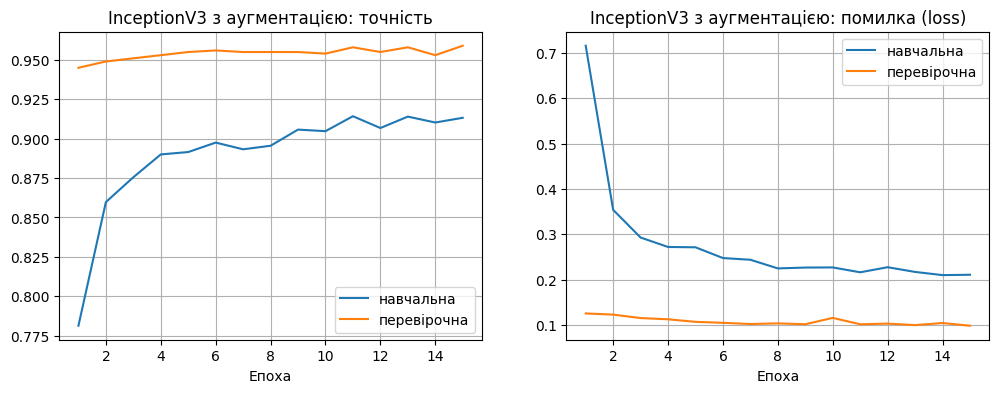

InceptionV3 з аугментацією: точність на тестових даних 95.60%


In [15]:
model_aug, _ = train(train_generator, 'InceptionV3 з аугментацією')

## Тонке налаштування: розморожено два модулі (mixed9, mixed10), найкраще в лабораторній 9

Розморожено блоків: 2, параметрів навчається: 15,827,457
Epoch 1/5
80/80 - 58s - 721ms/step - accuracy: 0.9143 - loss: 0.2150 - val_accuracy: 0.9610 - val_loss: 0.0939
Epoch 2/5
80/80 - 31s - 388ms/step - accuracy: 0.9270 - loss: 0.1810 - val_accuracy: 0.9630 - val_loss: 0.0949
Epoch 3/5
80/80 - 31s - 388ms/step - accuracy: 0.9335 - loss: 0.1544 - val_accuracy: 0.9660 - val_loss: 0.0895
Epoch 4/5
80/80 - 32s - 403ms/step - accuracy: 0.9365 - loss: 0.1557 - val_accuracy: 0.9670 - val_loss: 0.0765
Epoch 5/5
80/80 - 31s - 388ms/step - accuracy: 0.9420 - loss: 0.1384 - val_accuracy: 0.9690 - val_loss: 0.0774


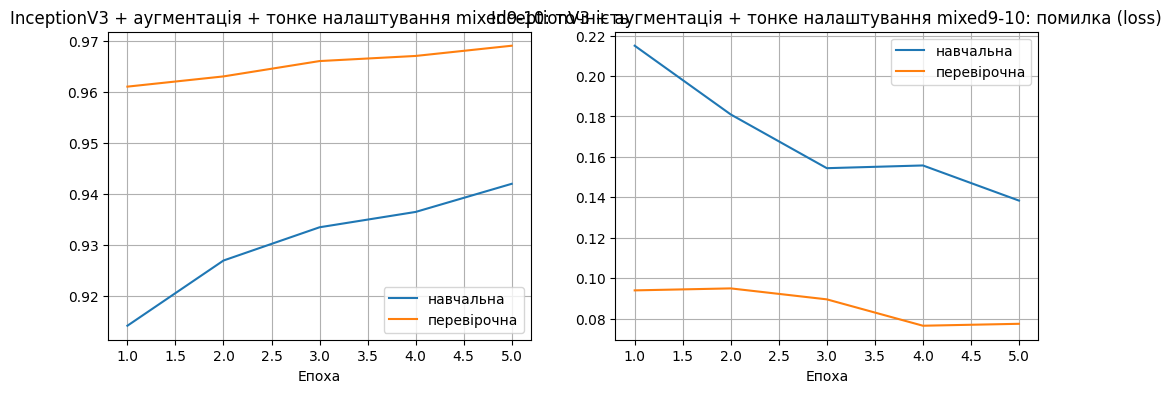

InceptionV3 + аугментація + тонке налаштування mixed9-10: точність на тестових даних 96.10%


In [16]:
model_ft2 = fine_tune(model_aug, None, 2, 'InceptionV3 + аугментація + тонке налаштування mixed9-10')

## Порівняння і збереження найкращої моделі на Google Диск

In [17]:
table = pd.DataFrame(results)
print(table.round(2))

candidates = [('без аугментації', model_noaug), ('з аугментацією', model_aug), ('тонке налаштування 2 модулі', model_ft2)]
best_title, best_model = max(candidates, key=lambda t: t[1].evaluate(test_generator, steps=len(test_generator), verbose=0)[1])
print('Найкраща модель:', best_title)

save_dir = '/content/drive/MyDrive/Lab10_models'
os.makedirs(save_dir, exist_ok=True)
best_model.save(os.path.join(save_dir, 'inceptionv3_aug_best.h5'), include_optimizer=False)
table.to_csv(os.path.join(save_dir, 'inceptionv3_aug_best_results.csv'), index=False)
!ls -lh {save_dir}

                                              модель  навчальна, %  \
0                        InceptionV3 без аугментації         97.25   
1                         InceptionV3 з аугментацією         91.33   
2  InceptionV3 + аугментація + тонке налаштування...         94.20   

   перевірочна, %  тестова, %  
0            96.3        95.3  
1            95.9        95.6  
2            96.9        96.1  


Найкраща модель: тонке налаштування 2 модулі
total 191M
-rw------- 1 root root 102M Oct 31 11:36 inceptionv3_aug_best.h5
-rw------- 1 root root  412 Oct 31 11:36 inceptionv3_aug_best_results.csv
-rw------- 1 root root  90M Oct 31 11:17 vgg16_aug_best.h5
-rw------- 1 root root  627 Oct 31 11:17 vgg16_aug_best_results.csv


## Розпізнавання власних зображень (ті самі, що в лабораторних роботах 7-9)

In [18]:
img_dirs = glob.glob('/content/drive/MyDrive/**/images_cats_dogs', recursive=True)
print(img_dirs)
assert img_dirs, 'Папку images_cats_dogs не знайдено на Google Диску'
for f in glob.glob(os.path.join(img_dirs[0], '*.jpg')):
    shutil.copy(f, '/content/')
print(len(glob.glob('/content/*.jpg')), 'зображень')

['/content/drive/MyDrive/Deep learning/images_cats_dogs']
47 зображень


In [19]:
def prepare(x):
    return preprocess_input(x)


def recognize(pattern, title):
    names = sorted(glob.glob(pattern))
    cols = 5
    rows = (len(names) + cols - 1) // cols
    plt.figure(figsize=(3 * cols, 3.4 * rows), dpi=60)
    correct = 0
    for i, fn in enumerate(names):
        img = load_img(fn, target_size=(img_width, img_height))
        x = np.expand_dims(prepare(img_to_array(img)), axis=0)
        p = float(best_model.predict(x, verbose=0)[0][0])     # ймовірність класу dogs
        pred = 'dog' if p > 0.5 else 'cat'
        true = 'dog' if 'dog' in os.path.basename(fn) else 'cat'
        correct += pred == true
        conf = p if pred == 'dog' else 1 - p
        print(f"{os.path.basename(fn)}: правильно - {true}, мережа - {pred} ({conf*100:.1f}%) {'✓' if pred == true else '✗'}")
        plt.subplot(rows, cols, i + 1)
        plt.imshow(img)
        plt.title(f"{os.path.basename(fn)}\n{pred} ({conf*100:.1f}%)", color='green' if pred == true else 'red')
        plt.axis('off')
    plt.suptitle(title)
    plt.show()
    print(f"Правильно розпізнано: {correct} з {len(names)}")

cat_01.jpg: правильно - cat, мережа - cat (99.6%) ✓
cat_02.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_03.jpg: правильно - cat, мережа - cat (99.9%) ✓
cat_04.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_05.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_06.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_07.jpg: правильно - cat, мережа - dog (63.8%) ✗
cat_08.jpg: правильно - cat, мережа - dog (97.3%) ✗
cat_09.jpg: правильно - cat, мережа - cat (99.8%) ✓
cat_10.jpg: правильно - cat, мережа - dog (81.3%) ✗


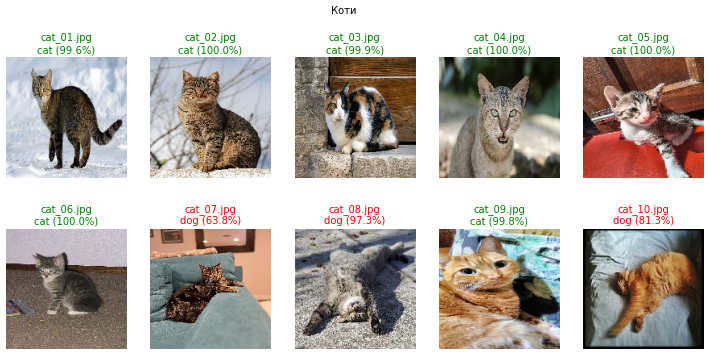

Правильно розпізнано: 7 з 10
dog_01.jpg: правильно - dog, мережа - dog (99.8%) ✓
dog_02.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_03.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_04.jpg: правильно - dog, мережа - dog (99.9%) ✓
dog_05.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_06.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_07.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_08.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_09.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_10.jpg: правильно - dog, мережа - dog (100.0%) ✓


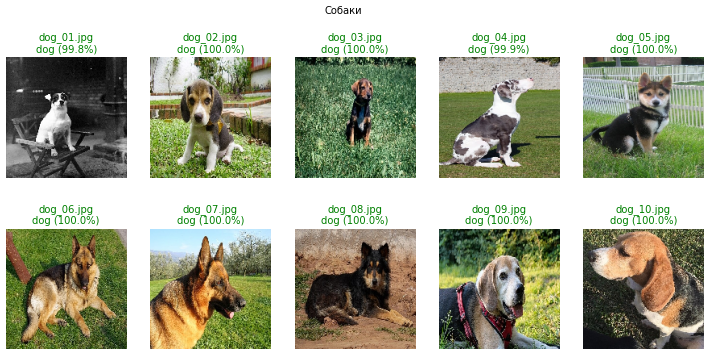

Правильно розпізнано: 10 з 10


In [20]:
recognize('cat_*.jpg', 'Коти')
recognize('dog_*.jpg', 'Собаки')

hard_cat_01.jpg: правильно - cat, мережа - cat (69.0%) ✓
hard_cat_02.jpg: правильно - cat, мережа - dog (71.6%) ✗
hard_cat_03.jpg: правильно - cat, мережа - cat (53.5%) ✓
hard_cat_04.jpg: правильно - cat, мережа - cat (56.7%) ✓
hard_cat_05.jpg: правильно - cat, мережа - cat (68.0%) ✓
hard_cat_06.jpg: правильно - cat, мережа - cat (79.8%) ✓
hard_cat_07.jpg: правильно - cat, мережа - cat (100.0%) ✓
hard_cat_08.jpg: правильно - cat, мережа - cat (99.0%) ✓
hard_cat_09.jpg: правильно - cat, мережа - dog (62.2%) ✗
hard_cat_10.jpg: правильно - cat, мережа - cat (81.5%) ✓
hard_dog_01.jpg: правильно - dog, мережа - dog (100.0%) ✓
hard_dog_02.jpg: правильно - dog, мережа - dog (76.6%) ✓
hard_dog_03.jpg: правильно - dog, мережа - dog (73.4%) ✓
hard_dog_04.jpg: правильно - dog, мережа - dog (79.7%) ✓
hard_dog_05.jpg: правильно - dog, мережа - dog (63.6%) ✓
hard_dog_06.jpg: правильно - dog, мережа - dog (100.0%) ✓
hard_dog_07.jpg: правильно - dog, мережа - dog (100.0%) ✓
hard_dog_08.jpg: правильно 

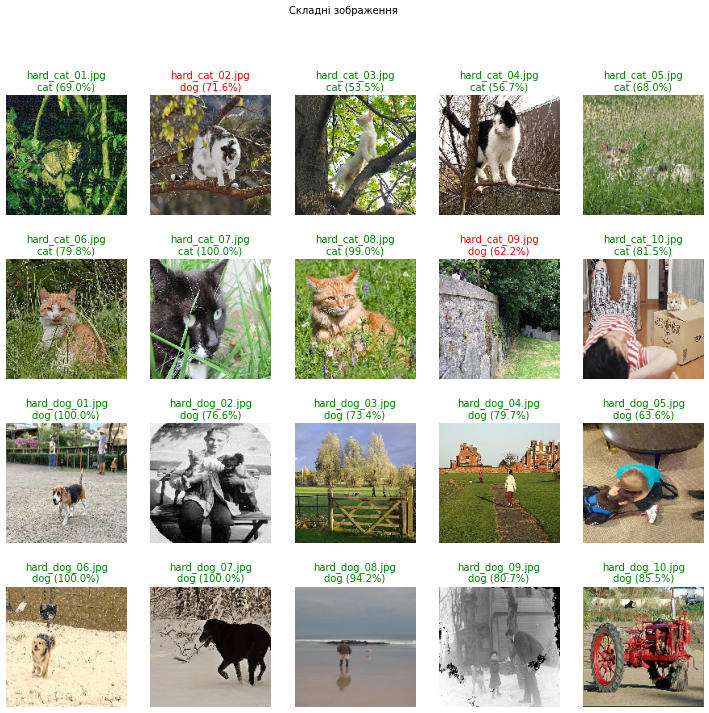

Правильно розпізнано: 18 з 20


In [21]:
recognize('hard_*.jpg', 'Складні зображення')

crop_cat_02.jpg: правильно - cat, мережа - cat (52.6%) ✓
crop_cat_03.jpg: правильно - cat, мережа - cat (72.0%) ✓
crop_cat_05.jpg: правильно - cat, мережа - cat (64.4%) ✓
crop_cat_06.jpg: правильно - cat, мережа - cat (99.2%) ✓
crop_cat_07.jpg: правильно - cat, мережа - cat (100.0%) ✓
crop_cat_08.jpg: правильно - cat, мережа - cat (96.6%) ✓
crop_dog_06.jpg: правильно - dog, мережа - dog (100.0%) ✓


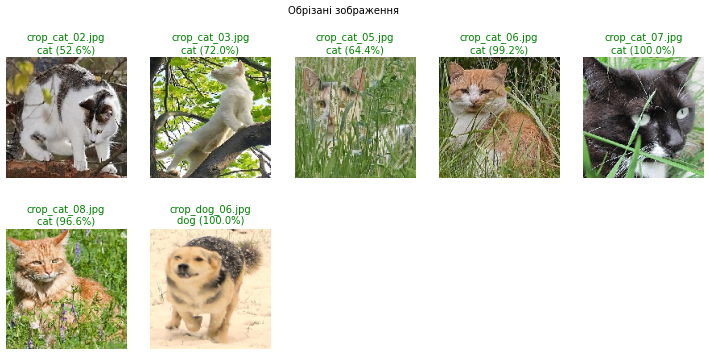

Правильно розпізнано: 7 з 7


In [22]:
recognize('crop_*.jpg', 'Обрізані зображення')